In [2]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [3]:
# Load data.pkl
with open('data.pkl', 'rb') as f:
    data = pickle.load(f)

# Load data.pkl
with open('splits/split.pkl', 'rb') as f:
    split = pickle.load(f)

# Load feat_dict.pkl
with open('feat_dict.pkl', 'rb') as f:
    feat_dict = pickle.load(f)

# Display types and basic info
type(data), type(split), type(feat_dict), len(data) if hasattr(data, '__len__') else None, len(split) if hasattr(split, '__len__') else None, len(feat_dict) if hasattr(feat_dict, '__len__') else None

(list, dict, dict, 9847, 3, 6)

In [4]:
# Pick a reaction (e.g., entry 400)
reaction_idx = 3000
reaction_data = data[reaction_idx]

# Extract NEB trajectory
pos_N_3_I = reaction_data.pos_N_3_I  # [atoms, 3, images]
num_atoms, _, num_images = pos_N_3_I.shape

print(f"Reaction {reaction_idx}:")
print(f"Number of atoms: {num_atoms}")
print(f"Number of NEB images: {num_images}")
print(f"SMILES: {reaction_data.smiles}")

# Convert to numpy for easier manipulation
neb_trajectory = pos_N_3_I.numpy()  # [atoms, 3, images]

# Reshape to [images, atoms, 3] for easier iteration
neb_images = neb_trajectory.transpose(2, 0, 1)  # [images, atoms, 3]

print(f"NEB images shape: {neb_images.shape}")

Reaction 3000:
Number of atoms: 13
Number of NEB images: 10
SMILES: [O:1]=[C:2]1[N:3]([H:8])[C:4]([H:9])([H:10])[C@@:5]2([H:11])[C:6]([H:12])([H:13])[N:7]12>>[O:1]([C:2]1=[N:3][C:4]([H:9])([H:10])[C@@:5]2([H:11])[C:6]([H:12])([H:13])[N:7]12)[H:8]
NEB images shape: (10, 13, 3)


In [ ]:
def save_individual_neb_images(neb_images, reaction_data, output_dir='neb_snapshots'):
    """
    Save each NEB image as individual XYZ file for external visualization
    """
    import os
    os.makedirs(output_dir, exist_ok=True)
    
    num_images, num_atoms, _ = neb_images.shape
    
    # Get atom types if available
    if hasattr(reaction_data, 'atom_type'):
        atom_types = reaction_data.atom_type.numpy()
        # Convert atom type indices to element symbols (you might need to adjust this)
        element_map = {1: 'H', 6: 'C', 7: 'N', 8: 'O', 16: 'S'}  # Add more as needed
        elements = [element_map.get(at, 'X') for at in atom_types]
    else:
        elements = ['C'] * num_atoms  # Default to carbon
    
    for img_idx in range(num_images):
        xyz_file = os.path.join(output_dir, f'neb_image_{img_idx:02d}.xyz')
        
        with open(xyz_file, 'w') as f:
            f.write(f"{num_atoms}\n")
            f.write(f"NEB Image {img_idx} - {reaction_data.smiles}\n")
            
            for atom_idx in range(num_atoms):
                pos = neb_images[img_idx, atom_idx]
                f.write(f"{elements[atom_idx]} {pos[0]:.6f} {pos[1]:.6f} {pos[2]:.6f}\n")
    
    print(f"Saved {num_images} XYZ files to {output_dir}/")

# Save individual frames
save_individual_neb_images(neb_images, reaction_data)

Saved 10 XYZ files to neb_snapshots/


In [26]:
from rdkit import Chem
import re

def strip_atom_mapping(smiles):
    # Remove atom mapping numbers, e.g. [O:1] -> [O]
    return re.sub(r'\:([0-9]+)', '', smiles)

def get_elements_from_smiles(smiles):
    # If reaction SMILES, take first reactant
    if '>>' in smiles:
        reactants = smiles.split('>>')[0]
        # If multiple reactants, take the first one
        reactant = reactants.split('.')[
            0] if '.' in reactants else reactants
    else:
        reactant = smiles
    reactant = strip_atom_mapping(reactant)
    mol = Chem.MolFromSmiles(reactant)
    if mol is None:
        raise ValueError("Invalid SMILES string after stripping atom mapping")
    return [atom.GetSymbol() for atom in mol.GetAtoms()]

# Example usage:
elements = get_elements_from_smiles(reaction_data.smiles)
print(elements)

# elements is the list from get_elements_from_smiles
num_atoms = neb_images.shape[1]
num_hydrogens = num_atoms - len(elements)
elements_with_h = elements + ['H'] * num_hydrogens
print(elements_with_h)

['O', 'C', 'N', 'C', 'N']
['O', 'C', 'N', 'C', 'N', 'H', 'H']


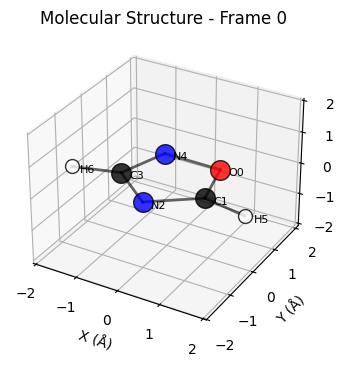

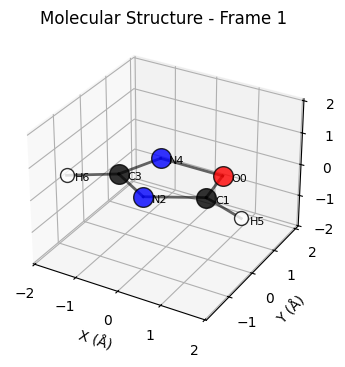

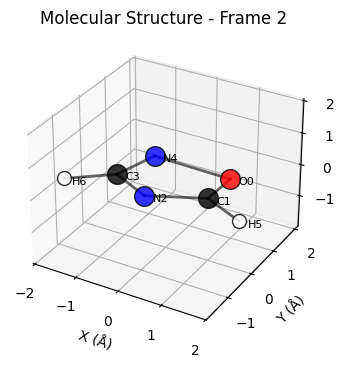

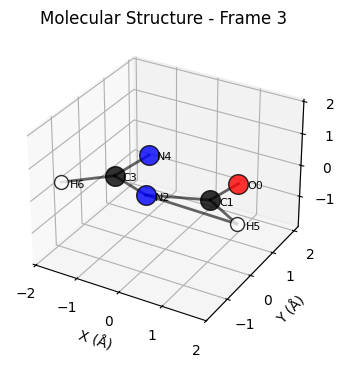

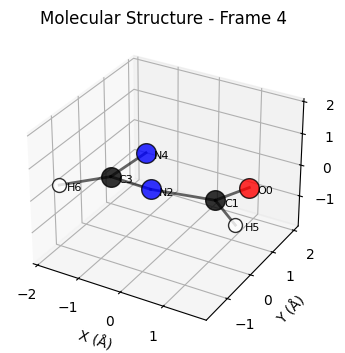

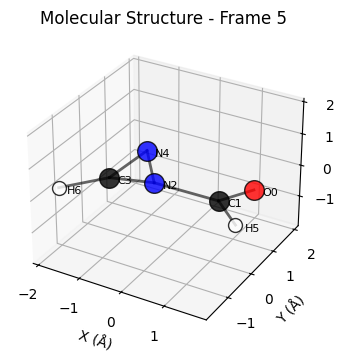

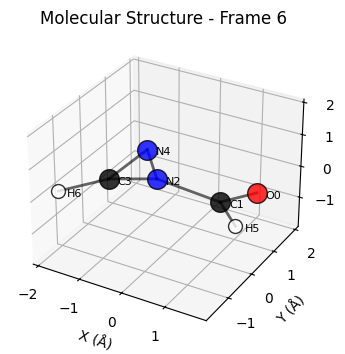

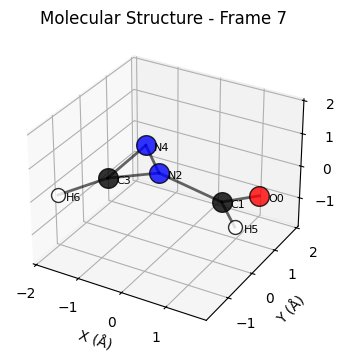

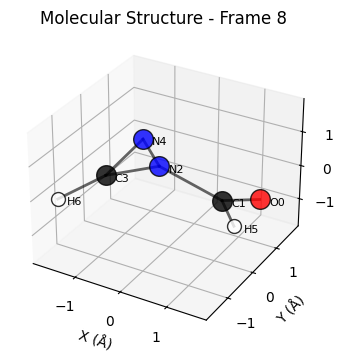

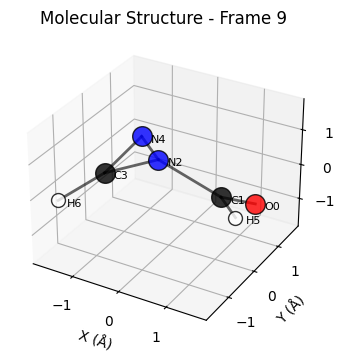

In [27]:
def plot_molecular_structure(neb_images, elements, frame_idx=0, 
                           atomic_colors=None, save_path=None):
    """
    Plot single molecular structure with proper atomic colors
    """
    if atomic_colors is None:
        # Standard CPK colors
        atomic_colors = {
            'H': 'white', 'C': 'black', 'N': 'blue', 'O': 'red', 
            'S': 'yellow', 'P': 'orange', 'F': 'lightgreen',
            'Cl': 'green', 'Br': 'darkred', 'I': 'purple'
        }
    
    fig = plt.figure(figsize=(6, 4))
    ax = fig.add_subplot(111, projection='3d')
    
    positions = neb_images[frame_idx]
    
    # Plot atoms
    for i, (pos, element) in enumerate(zip(positions, elements)):
        color = atomic_colors.get(element, 'gray')
        size = 200 if element != 'H' else 100  # Smaller for hydrogen
        ax.scatter(pos[0], pos[1], pos[2], 
                  c=color, s=size, alpha=0.8, 
                  edgecolors='black', linewidth=1)
        
        # Add atom labels
        # Offset label to the side (e.g., along +x direction)
        offset = 0.2  # adjust as needed for clarity
        ax.text(pos[0] + offset, pos[1], pos[2], f'{element}{i}', 
            fontsize=8, ha='left', va='center')
    
    # Draw bonds (simple distance-based)
    for i in range(len(positions)):
        for j in range(i+1, len(positions)):
            dist = np.linalg.norm(positions[i] - positions[j])
            # Typical bond lengths (adjust as needed)
            max_bond_length = 2.0  # Angstroms
            if dist < max_bond_length:
                ax.plot([positions[i][0], positions[j][0]],
                       [positions[i][1], positions[j][1]],
                       [positions[i][2], positions[j][2]], 
                       'k-', alpha=0.6, linewidth=2)
    
    ax.set_xlabel('X (Å)')
    ax.set_ylabel('Y (Å)')
    ax.set_zlabel('Z (Å)')
    ax.set_title(f'Molecular Structure - Frame {frame_idx}')
    
    # Equal aspect ratio
    max_range = np.array([positions[:,0].max()-positions[:,0].min(),
                         positions[:,1].max()-positions[:,1].min(),
                         positions[:,2].max()-positions[:,2].min()]).max() / 2.0
    mid_x = (positions[:,0].max()+positions[:,0].min()) * 0.5
    mid_y = (positions[:,1].max()+positions[:,1].min()) * 0.5
    mid_z = (positions[:,2].max()+positions[:,2].min()) * 0.5
    ax.set_xlim(mid_x - max_range, mid_x + max_range)
    ax.set_ylim(mid_y - max_range, mid_y + max_range)
    ax.set_zlim(mid_z - max_range, mid_z + max_range)
    
    # if save_path:
        # plt.savefig(save_path, dpi=300, bbox_inches='tight')
    
    plt.show()
    return fig, ax

# Usage
for i in range(len(neb_images)):
    plot_molecular_structure(neb_images, elements_with_h, frame_idx=i)